# №4. Сдвиг и поворот

Цель: выполнить геометрические преобразования и сравнить два способа интерполяции.

Координата $x$ растёт вправо, $y$ — вниз. Индексация массива: `image[y, x]`.
Сдвиг $(d_x, d_y)$ положителен вправо и вниз. Положительный угол поворачивает
картинку против часовой стрелки. Размер холста сохраняется, внешняя область заполняется нулём.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    figsize = figsize or (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    fig.tight_layout()
    plt.show()

Размер исходного изображения: (300, 300, 3)


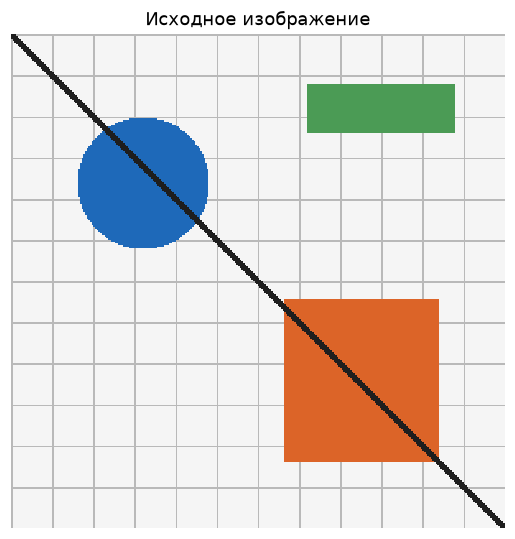

In [3]:
image = np.array(Image.open("data/geometry.png").convert("RGB"))
print("Размер исходного изображения:", image.shape)
show_images([image], ["Исходное изображение"], cols=1, figsize=(5, 5))

## 1. Сдвиг на целое число пикселей

Пересечение исходного и нового холста переносится срезами массива.

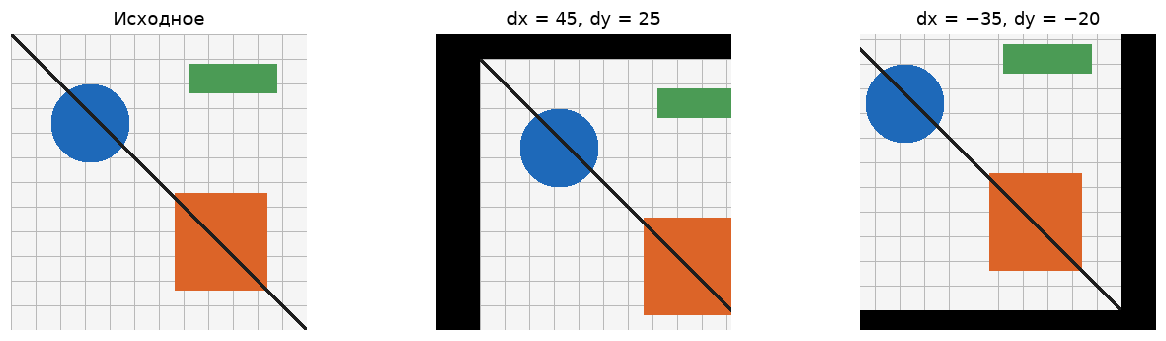

In [4]:
def shift_integer(image, dx, dy, background=0):
    """Целочисленный перенос с постоянным фоном."""
    h, w = image.shape[:2]
    result = np.full_like(image, background)
    x0, x1 = max(0, -dx), min(w, w - dx)
    y0, y1 = max(0, -dy), min(h, h - dy)
    if x1 > x0 and y1 > y0:
        result[y0 + dy:y1 + dy, x0 + dx:x1 + dx] = image[y0:y1, x0:x1]
    return result

show_images([image, shift_integer(image, 45, 25), shift_integer(image, -35, -20)],
            ["Исходное", "dx = 45, dy = 25", "dx = −35, dy = −20"])

## 2. Дробный сдвиг

Для каждого пикселя результата вычисляем координату в исходной картинке:
$x=x'-d_x$, $y=y'-d_y$. Ближайший сосед округляет её до центра пикселя.
Билинейная интерполяция смешивает четыре ближайших значения:

$$f(x,y)=(1-u)(1-v)f_{00}+u(1-v)f_{10}+(1-u)vf_{01}+uvf_{11}.$$

Здесь $u=x-\lfloor x\rfloor$, $v=y-\lfloor y\rfloor$.
За границей холста каждый из четырёх отсчётов принимает значение фона.

In [5]:
def sample_image(image, x, y, method="bilinear", background=0):
    """Значения изображения в вещественных координатах x, y."""
    source = np.asarray(image, dtype=float)
    h, w = source.shape[:2]
    x = np.clip(x, -2, w + 1)
    y = np.clip(y, -2, h + 1)

    def get_pixel(ix, iy):
        valid = (ix >= 0) & (ix < w) & (iy >= 0) & (iy < h)
        values = source[np.clip(iy, 0, h - 1), np.clip(ix, 0, w - 1)]
        if source.ndim == 3:
            valid = valid[..., None]
        return np.where(valid, values, background)

    if method == "nearest":
        return get_pixel(np.floor(x + 0.5).astype(int), np.floor(y + 0.5).astype(int))

    x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
    wx, wy = x - x0, y - y0
    if source.ndim == 3:
        wx, wy = wx[..., None], wy[..., None]
    return ((1 - wx) * (1 - wy) * get_pixel(x0, y0)
            + wx * (1 - wy) * get_pixel(x0 + 1, y0)
            + (1 - wx) * wy * get_pixel(x0, y0 + 1)
            + wx * wy * get_pixel(x0 + 1, y0 + 1))

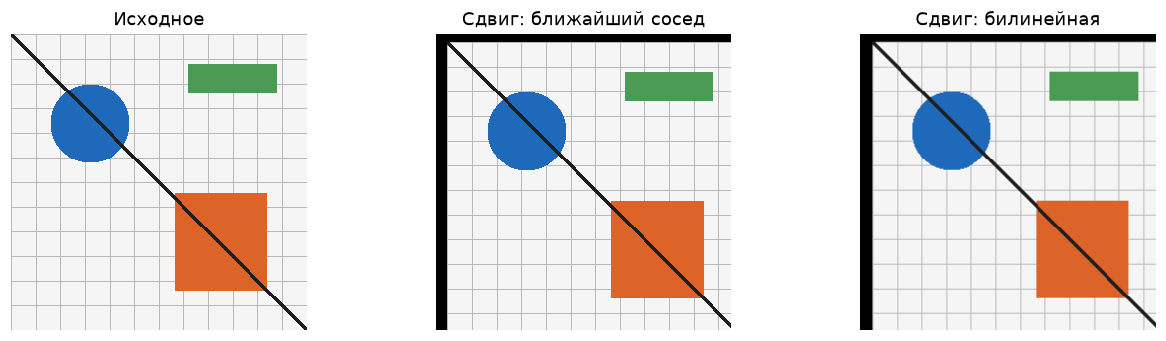

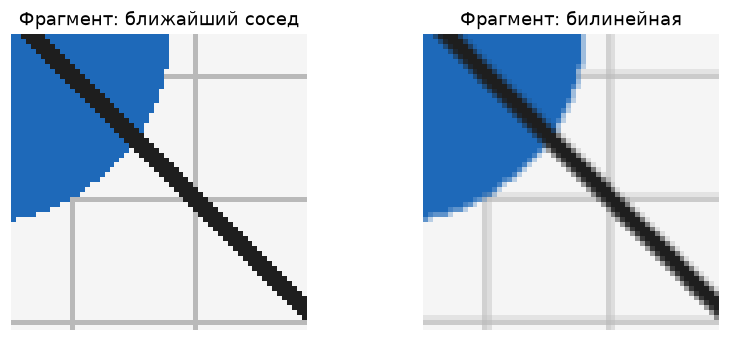

In [6]:
def shift_fractional(image, dx, dy, method="bilinear", background=0):
    y, x = np.indices(image.shape[:2], dtype=float)
    return sample_image(image, x - dx, y - dy, method, background)

nearest = shift_fractional(image, 12.4, 7.7, "nearest")
bilinear = shift_fractional(image, 12.4, 7.7, "bilinear")
show_images([image, to_uint8(nearest), to_uint8(bilinear)],
            ["Исходное", "Сдвиг: ближайший сосед", "Сдвиг: билинейная"])

# Увеличенный фрагмент показывает различия на границах.
h, w = image.shape[:2]
y0, x0 = h // 3, w // 3
region = np.s_[y0:y0 + 60, x0:x0 + 60]
show_images([to_uint8(nearest[region]), to_uint8(bilinear[region])],
            ["Фрагмент: ближайший сосед", "Фрагмент: билинейная"], cols=2)

## 3. Поворот

Центр поворота: $c_x=(W-1)/2$, $c_y=(H-1)/2$.
Обратное отображение учитывает направление вертикальной оси:

$$x=c_x+\cos\theta(x'-c_x)-\sin\theta(y'-c_y),$$
$$y=c_y+\sin\theta(x'-c_x)+\cos\theta(y'-c_y).$$

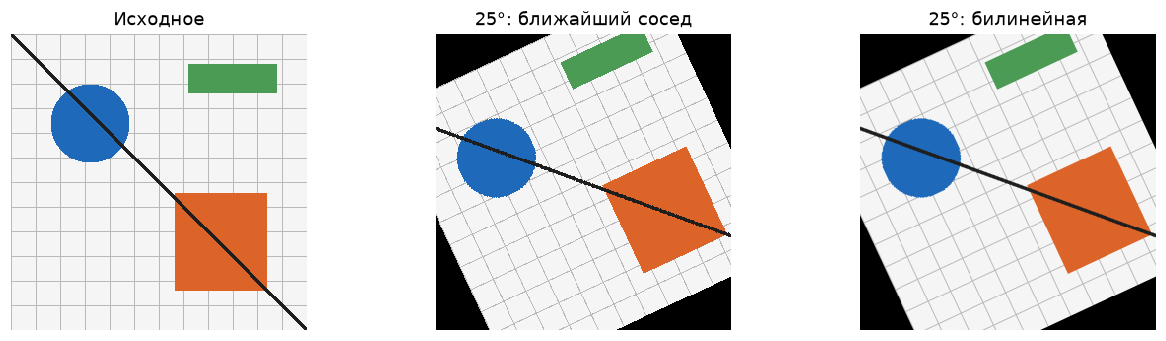

In [7]:
def rotate(image, angle, method="bilinear", background=0):
    y, x = np.indices(image.shape[:2], dtype=float)
    h, w = image.shape[:2]
    cx, cy = (w - 1) / 2, (h - 1) / 2
    theta = np.deg2rad(angle)
    source_x = cx + np.cos(theta) * (x - cx) - np.sin(theta) * (y - cy)
    source_y = cy + np.sin(theta) * (x - cx) + np.cos(theta) * (y - cy)
    return sample_image(image, source_x, source_y, method, background)

show_images([image, to_uint8(rotate(image, 25, "nearest")),
             to_uint8(rotate(image, 25, "bilinear"))],
            ["Исходное", "25°: ближайший сосед", "25°: билинейная"])

## Вывод

Целый сдвиг сохраняет значения перенесённых пикселей. Ближайший сосед сохраняет
исходные уровни и формирует ступеньки на наклонных линиях. Билинейная интерполяция
делает переходы плавнее за счёт промежуточных уровней. При повороте часть изображения
выходит за фиксированный холст; освободившиеся области получают значение фона.